# Impacto do Refinamento Meta-heurístico: AisleBased vs. ILS-VND

**Objetivo:** Quantificar o ganho obtido ao refinar a solução inicial $s_0$ (heurística construtiva *AisleBased*) com a meta-heurística *ILS-VND*, resultando em $s^*$, nos datasets A, B e X ($50$ instâncias).

## Tabelas e Figuras Geradas

| Identificador | Título / Conteúdo | Objetivo |
|:---:|---|---|
| **T2.1** (`tab_2_1`) | Evolução de $s_0$ para $s^*$ (gap): AisleBased, ILS-VND (média das 5 réplicas) e ILS-VND (melhor das 5 réplicas) por dataset | Mediana, Média (DP), P90, Máx., Gap $\le 1\%$ ($n/N$) e MSC igualadas ou superadas (Gap $\le 0\%$) |
| **T2.2** (`tab_2_2`) | Ganho de refinamento e estabilidade | V–E–D do ILS-VND contra o AisleBased, redução média e máxima de gap (p.p.), DP médio entre as 5 sementes e $p$-valor de Wilcoxon |
| **T2.3** (`tab_2_3`) | Alteração estrutural pós-refinamento | Mediana e média de unidades e corredores antes e depois; origem do ganho |
| **F2.1** (`fig_2_1`) | Dumbbell plot da redução de gap | Instâncias com Gap do AisleBased $> 1\%$: $s_0 \to s^*$ |
| **F2.2** (`fig_2_2`) | Barras agrupadas de faixas de qualidade | Proporção das 50 instâncias por faixa de gap antes e depois do ILS-VND |

## Convenções do Estudo

- **Unidade estatística:** instância. O AisleBased é determinístico (as réplicas são idênticas em qualidade). Para o ILS-VND usam-se as **5 primeiras réplicas** (`run_id` $1$ a $5$, `N_REPS = 5`) de `project/results/ils_vnd_all` (que contém 30).
- **Gap (%):** $\frac{\text{MSC} - \text{obtido}}{\text{MSC}} \times 100$, calculado por execução. *ILS-VND (média)*: média do gap das 5 réplicas por instância. *ILS-VND (melhor)*: menor gap entre as 5 réplicas por instância. Gap negativo indica MSC superada.
- **Redução de gap (p.p.):** $\text{gap}(s_0) - \text{gap}(s^*)$, com $s^*$ = ILS-VND (média das 5 réplicas).
- **V–E–D:** vitórias / empates / derrotas do ILS-VND (média) contra o AisleBased; vitória = gap estritamente menor (tolerância $10^{-9}$).
- **Wilcoxon:** teste de postos sinalizados pareado, unilateral ($H_1$: gap do AisleBased $>$ gap do ILS-VND), zeros descartados (`zero_method="wilcox"`).
- **Formatação LaTeX (abnTeX2):** `booktabs`, `\small`, vírgula decimal.


## 1. Configuração

In [1]:
import sys
import os
from pathlib import Path

# ── Localização da raiz do repositório ───────────────────────────────────────
_candidate = Path.cwd()
ROOT = None
for _p in [_candidate] + list(_candidate.parents):
    if (_p / "notebooks" / "utils" / "__init__.py").exists():
        ROOT = _p
        break
if ROOT is None:
    raise RuntimeError("Raiz do repositório não encontrada (notebooks/utils/__init__.py ausente).")

# ── Caminhos principais ───────────────────────────────────────────────────────
RESULTS_BASE   = ROOT / "project" / "results"
DATASETS_BASE  = ROOT / "datasets"
BEST_SOL_BASE  = ROOT / "best_solutions"
BEST_OBJ_CSV   = BEST_SOL_BASE / "best_objectives.csv"
VALIDATOR_DIR  = ROOT / "project" / "validator"
UTILS_DIR      = ROOT / "notebooks" / "utils"
OUTPUT_DIR     = ROOT / "notebooks" / "experimentos" / "output" / "refinamento_ils_vnd"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Adiciona os diretórios ao sys.path
for _d in [str(ROOT / "notebooks"), str(VALIDATOR_DIR), str(ROOT)]:
    if _d not in sys.path:
        sys.path.insert(0, _d)

# ── Constantes ────────────────────────────────────────────────────────────────
TOL         = 1e-9          # tolerância para empates em comparações
SEED        = 42            # semente aleatória global
DATASETS    = ["a", "b", "x"]
N_REPS      = 5             # réplicas do ILS-VND consideradas (run_id 1..N_REPS)
DS_LABELS   = {"a": "A", "b": "B", "x": "X"}
ALGOS       = ["aisle_based", "ils_vnd"]
ALGO_LABELS = {"aisle_based": "AisleBased", "ils_vnd": "ILS-VND"}

# ── Estilo de figuras ─────────────────────────────────────────────────────────
FIG_W      = 6.3           # largura útil da página em polegadas
FIG_H1     = 3.8           # altura fig_1
FIG_H2     = 3.4           # altura fig_2
FONT_MIN   = 9             # fonte mínima em pt

# Cores padrão do matplotlib (tab:blue e tab:orange) para diferenciação por algoritmo
COLORS = {
    "aisle_based": "tab:blue",     # azul padrão (C0)
    "ils_vnd": "tab:green",           # verde padrão (C2)
}
MARKERS = {
    "aisle_based": "o",            # círculo
    "ils_vnd": "s",                   # quadrado
}

# ── Configuração global de matplotlib ────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
plt.rcParams.update({
    "font.size":        FONT_MIN,
    "axes.titlesize":   FONT_MIN,
    "axes.labelsize":   FONT_MIN,
    "xtick.labelsize":  FONT_MIN,
    "ytick.labelsize":  FONT_MIN,
    "legend.fontsize":  FONT_MIN,
    "figure.dpi":       150,
    "savefig.dpi":      300,
    "pdf.fonttype":     42,
    "ps.fonttype":      42,
})

print("ROOT          :", ROOT)
print("RESULTS_BASE  :", RESULTS_BASE)
print("DATASETS_BASE :", DATASETS_BASE)
print("BEST_OBJ_CSV  :", BEST_OBJ_CSV)
print("VALIDATOR_DIR :", VALIDATOR_DIR)
print("OUTPUT_DIR    :", OUTPUT_DIR)


ROOT          : /home/vinicius/Documents/CEFET/TCC/pfc2
RESULTS_BASE  : /home/vinicius/Documents/CEFET/TCC/pfc2/project/results
DATASETS_BASE : /home/vinicius/Documents/CEFET/TCC/pfc2/datasets
BEST_OBJ_CSV  : /home/vinicius/Documents/CEFET/TCC/pfc2/best_solutions/best_objectives.csv
VALIDATOR_DIR : /home/vinicius/Documents/CEFET/TCC/pfc2/project/validator
OUTPUT_DIR    : /home/vinicius/Documents/CEFET/TCC/pfc2/notebooks/experimentos/output/refinamento_gvns


## 2. Utilitários

In [2]:
import re
import io
import csv
import tempfile
import numpy as np
import pandas as pd
from scipy import stats

# ── Formatador numérico com vírgula decimal ───────────────────────────────────
def fmt(value, decimals=2):
    """Formata número com vírgula como separador decimal."""
    if pd.isna(value):
        return "--"
    if isinstance(value, (int, np.integer)):
        return f"{int(value)}"
    fmt_str = f"{value:.{decimals}f}"
    return fmt_str.replace(".", ",")

# ── Escape LaTeX ──────────────────────────────────────────────────────────────
def tex_escape(text, raw=False):
    """Escapa texto para LaTeX. Se raw=True, retorna sem escape (modo matemático)."""
    if raw:
        return str(text)
    s = str(text)
    s = s.replace("\\", r"\textbackslash{}")
    s = s.replace("&",  r"\&")
    s = s.replace("%",  r"\%")
    s = s.replace("#",  r"\#")
    s = s.replace("_",  r"\_")
    s = s.replace("{",  r"\{")
    s = s.replace("}",  r"\}")
    s = s.replace("~",  r"\textasciitilde{}")
    s = s.replace("^",  r"\textasciicircum{}")
    return s

# ── Escritor de tabular booktabs ──────────────────────────────────────────────
def make_tabular(header_rows, data_rows, col_align, raw_cols=None):
    if raw_cols is None:
        raw_cols = set()

    lines = []
    lines.append(r"\small")
    lines.append(r"\begin{tabular}{" + col_align + "}")
    lines.append(r"\toprule")

    for h_row in header_rows:
        cells_tex = []
        for j, cell in enumerate(h_row):
            if isinstance(cell, tuple):
                txt, is_raw = cell
            else:
                txt, is_raw = cell, (j in raw_cols)
            cells_tex.append(tex_escape(txt, raw=is_raw))
        lines.append(" & ".join(cells_tex) + r" \\")
    lines.append(r"\midrule")

    for row in data_rows:
        cells_tex = []
        for j, cell in enumerate(row):
            if isinstance(cell, tuple):
                txt, is_raw = cell
            else:
                txt, is_raw = cell, (j in raw_cols)
            cells_tex.append(tex_escape(str(txt), raw=is_raw))
        lines.append(" & ".join(cells_tex) + r" \\")

    lines.append(r"\bottomrule")
    lines.append(r"\end{tabular}")
    return "\n".join(lines)

# ── Gravador CSV + .tex ───────────────────────────────────────────────────────
def salvar_tabela(nome, df_csv, tex_str, output_dir=OUTPUT_DIR):
    csv_path = output_dir / f"{nome}.csv"
    tex_path = output_dir / f"{nome}.tex"
    df_csv.to_csv(csv_path, index=False)
    tex_path.write_text(tex_str, encoding="utf-8")
    return csv_path, tex_path

# ── Teste de sinais exato bilateral ──────────────────────────────────────────
def teste_sinais(diffs):
    diffs = np.asarray(diffs, dtype=float)
    diffs_nonzero = diffs[np.abs(diffs) > TOL]
    n = len(diffs_nonzero)
    if n == 0:
        return np.nan
    k = int(np.sum(diffs_nonzero > 0))
    result = stats.binomtest(k, n, p=0.5, alternative="two-sided")
    return result.pvalue

# ── Resumo pareado ────────────────────────────────────────────────────────────
def resumo_pareado(vals_a, vals_b, maior_e_melhor_a=False):
    a = np.asarray(vals_a, dtype=float)
    b = np.asarray(vals_b, dtype=float)
    diffs = a - b
    if maior_e_melhor_a:
        wins   = int(np.sum(diffs >  TOL))
        losses = int(np.sum(diffs < -TOL))
    else:
        wins   = int(np.sum(diffs < -TOL))
        losses = int(np.sum(diffs >  TOL))
    ties = len(diffs) - wins - losses
    return wins, ties, losses, diffs

# ── Verificação estrutural de .tex ────────────────────────────────────────────
def verificar_tex(tex_str, nome=""):
    erros = []
    if re.search(r'\\\\(begin|end|toprule|midrule|bottomrule|small)', tex_str):
        erros.append("barras duplicadas em comandos estruturais")
    begins = re.findall(r'\\begin\{(\w+)\}', tex_str)
    ends   = re.findall(r'\\end\{(\w+)\}', tex_str)
    if sorted(begins) != sorted(ends):
        erros.append(f"begin/end desbalanceados: {begins} vs {ends}")
    tex_lines = [l for l in tex_str.split("\n") if l.strip().endswith(r"\\") and "&" in l]
    counts = [l.count("&") for l in tex_lines]
    if len(set(counts)) > 1:
        erros.append(f"número de & inconsistente por linha: {set(counts)}")
    return erros

# ─── Auto-teste ───────────────────────────────────────────────────────────────
with tempfile.TemporaryDirectory() as _tmpdir:
    _hdr = [["Dataset", "Algoritmo", "Mediana", "Média"]]
    _dat = [
        ["A", "AisleBased", fmt(1.23), fmt(2.34)],
        ["B", "OrderBased", fmt(5.67), fmt(6.78)],
    ]
    _tex = make_tabular(_hdr, _dat, "llrr")
    _erros = verificar_tex(_tex, "auto-teste")
    if _erros:
        print("AUTO-TESTE FALHOU:", _erros)
    else:
        print("Auto-teste dos utilitários: ok")
    assert "1,23" in _tex and "2,34" in _tex, "vírgula decimal ausente"
    print("Vírgula decimal: ok")


Auto-teste dos utilitários: ok
Vírgula decimal: ok


## 3. Carga dos Resultados

In [3]:
from utils.resultados import carregar_resultados

df_aisle = carregar_resultados("aisle_based", RESULTS_BASE)
df_aisle["algo_id"] = "aisle_based"

df_ils_vnd = carregar_resultados("ils_vnd_all", RESULTS_BASE)
print("Execuções ILS-VND disponíveis por instância:", df_ils_vnd.groupby(["dataset", "instance"]).size().unique())
df_ils_vnd = df_ils_vnd[df_ils_vnd["run_id"] <= N_REPS].copy()
df_ils_vnd["algo_id"] = "ils_vnd"

df_raw = pd.concat([df_aisle, df_ils_vnd], ignore_index=True)
print(f"ILS-VND: mantidas as {N_REPS} primeiras réplicas por instância.")
print("Número de execuções por algoritmo e dataset:")
_ct = df_raw.groupby(["algo_id", "dataset"]).size().unstack(fill_value=0)
_ct.columns = [DS_LABELS.get(c, c) for c in _ct.columns]
_ct.index = [ALGO_LABELS.get(i, i) for i in _ct.index]
display(_ct)

_infeasible = df_raw[df_raw["status"] != "feasible"]
if len(_infeasible) == 0:
    print(f"Nenhuma execução inviável (todas as {len(df_raw)} execuções são 'feasible').")
else:
    print(f"ATENÇÃO: {len(_infeasible)} execução(ões) inviável(is) descartada(s):")
    display(_infeasible[["dataset", "instance", "algo_id", "status"]].drop_duplicates())
df_viable = df_raw[df_raw["status"] == "feasible"].copy()


Execuções GVNS disponíveis por instância: [30]
GVNS: mantidas as 5 primeiras réplicas por instância.
Número de execuções por algoritmo e dataset:


,A,B,X
AisleBased,600,450,450
GVNS,100,75,75


Nenhuma execução inviável (todas as 1750 execuções são 'feasible').


## 4. MSC, Gap e Agregação por Instância

In [4]:
# ── MSC e gap por execução ───────────────────────────────────────────────────
_msc_raw = pd.read_csv(BEST_OBJ_CSV)
_msc_raw["instance"] = _msc_raw["instance"].str.strip().str.replace("\r", "", regex=False)
_msc_raw["instance_key"] = _msc_raw["instance"].str.replace(".txt", "", regex=False)
_msc_raw["dataset"] = _msc_raw["dataset"].str.strip()
msc_dict = {(r["dataset"], r["instance_key"]): r["best_objective"] for _, r in _msc_raw.iterrows()}
print(f"MSC carregadas: {len(msc_dict)}")

df_viable["msc"] = df_viable.apply(lambda r: msc_dict.get((r["dataset"], r["instance"]), np.nan), axis=1)
df_viable["gap"] = (df_viable["msc"] - df_viable["objective"]) / df_viable["msc"] * 100.0

# ── Agregação por instância ──────────────────────────────────────────────────
_g = df_viable.groupby(["dataset", "instance", "algo_id"])
df_inst = _g.agg(
    gap_media=("gap", "mean"),
    gap_melhor=("gap", "min"),
    gap_dp=("gap", lambda s: s.std(ddof=1) if len(s) > 1 else 0.0),
    items=("items", "mean"),
    aisles=("aisles", "mean"),
    n_runs=("gap", "size"),
    msc=("msc", "first"),
).reset_index()

# Pareamento por instância (uma linha por instância)
_a = df_inst[df_inst["algo_id"] == "aisle_based"].set_index(["dataset", "instance"])
_v = df_inst[df_inst["algo_id"] == "ils_vnd"].set_index(["dataset", "instance"])
_idx = _a.index.intersection(_v.index)
df_par = pd.DataFrame({
    "gap_s0":        _a.loc[_idx, "gap_media"],
    "gap_ils_vnd_med":  _v.loc[_idx, "gap_media"],
    "gap_ils_vnd_best": _v.loc[_idx, "gap_melhor"],
    "gap_ils_vnd_dp":   _v.loc[_idx, "gap_dp"],
    "items_s0":      _a.loc[_idx, "items"],
    "items_ils_vnd":    _v.loc[_idx, "items"],
    "aisles_s0":     _a.loc[_idx, "aisles"],
    "aisles_ils_vnd":   _v.loc[_idx, "aisles"],
}).reset_index()
df_par["reducao_pp"] = df_par["gap_s0"] - df_par["gap_ils_vnd_med"]

print("Instâncias pareadas:", len(df_par), "| runs ILS-VND por instância:", sorted(_v["n_runs"].unique()),
      "| runs AisleBased por instância (média usada):", sorted(_a["n_runs"].unique()))
print("Gaps negativos (MSC superada) — AisleBased:", int((df_par.gap_s0 < -TOL).sum()),
      "| ILS-VND média:", int((df_par.gap_ils_vnd_med < -TOL).sum()),
      "| ILS-VND melhor:", int((df_par.gap_ils_vnd_best < -TOL).sum()))
display(df_par.head())


MSC carregadas: 50
Instâncias pareadas: 50 | runs GVNS por instância: [np.int64(5)] | runs AisleBased por instância (média usada): [np.int64(30)]
Gaps negativos (MSC superada) — AisleBased: 0 | GVNS média: 2 | GVNS melhor: 2


,dataset,instance,gap_s0,gap_gvns_med,gap_gvns_best,gap_gvns_dp,items_s0,items_gvns,aisles_s0,aisles_gvns,reducao_pp
0,a,instance_0001,0.000000,0.0,0.0,0.0,30.0,30.0,2.0,2.0,0.000000
1,a,instance_0002,0.000000,0.0,0.0,0.0,2.0,2.0,1.0,1.0,0.000000
2,a,instance_0003,29.166667,0.0,0.0,0.0,34.0,48.0,4.0,4.0,29.166667
3,a,instance_0004,0.000000,0.0,0.0,0.0,7.0,7.0,2.0,2.0,0.000000
4,a,instance_0005,3.092059,0.0,0.0,0.0,1379.0,1423.0,8.0,8.0,3.092059


## 5. Tabela 2.1: Evolução da Solução Inicial ($s_0$) para a Solução Refinada ($s^*$)

**Objetivo:** Comparar a distribuição de gap do AisleBased ($s_0$) com a do ILS-VND, tanto na média quanto na melhor das 5 réplicas.

### Legenda e Descrição das Colunas
* **Dataset:** `A` (20), `B` (15), `X` (15) ou `Geral` (50 instâncias).
* **Método:** `AisleBased` ($s_0$); `ILS-VND (média)` — média do gap das 5 réplicas; `ILS-VND (melhor)` — melhor réplica.
* **Mediana:** mediana do gap (%) entre as instâncias.
* **Média (DP):** média e desvio padrão amostral do gap (%).
* **P90:** percentil 90 do gap (%).
* **Máx.:** maior gap (%).
* **Gap $\le 1\%$ ($n/N$):** instâncias com gap $\le 1\%$.
* **MSC ($n/N$):** instâncias em que a MSC foi igualada ou superada (Gap $\le 0\%$).


In [5]:
METODOS_21 = [("AisleBased", "gap_s0"), ("ILS-VND (média)", "gap_ils_vnd_med"), ("ILS-VND (melhor)", "gap_ils_vnd_best")]

def resumo_21(df):
    rows = []
    for nome, col in METODOS_21:
        g = df[col].dropna()
        rows.append({
            "metodo": nome, "mediana": g.median(), "media": g.mean(), "dp": g.std(ddof=1),
            "p90": g.quantile(0.90), "maximo": g.max(),
            "n_le1": int((g <= 1.0 + TOL).sum()), "n_msc": int((g <= TOL).sum()), "N": len(g),
        })
    return rows

HEADER_21 = [["Dataset", "Método", "Mediana", "Média (DP)", "P90", "Máx.",
              (r"Gap $\leq$ 1\% ($n$/$N$)", True), (r"MSC ($n$/$N$)", True)]]
csv21, tex21 = [], []
for ds in DATASETS + [None]:
    lbl = DS_LABELS[ds] if ds else "Geral"
    sub = df_par[df_par["dataset"] == ds] if ds else df_par
    for i, r in enumerate(resumo_21(sub)):
        csv21.append([lbl, r["metodo"], r["mediana"], r["media"], r["dp"], r["p90"], r["maximo"],
                      f"{r['n_le1']}/{r['N']}", f"{r['n_msc']}/{r['N']}"])
        tex21.append([lbl if i == 0 else "", r["metodo"], fmt(r["mediana"]),
                      f"{fmt(r['media'])} ({fmt(r['dp'])})", fmt(r["p90"]), fmt(r["maximo"]),
                      (f"{r['n_le1']}/{r['N']}", False), (f"{r['n_msc']}/{r['N']}", False)])

df_tab21 = pd.DataFrame(csv21, columns=["Dataset", "Metodo", "Mediana", "Media", "DP", "P90", "Max", "Gap_le1_nN", "MSC_nN"])
tex_21 = make_tabular(HEADER_21, tex21, "llrrrrrr", raw_cols={6, 7})
LEG_21 = """% Legenda:
% - Dataset: A (20), B (15), X (15) ou Geral (50 instâncias).
% - Método: AisleBased (s0); ILS-VND (média das 5 réplicas); ILS-VND (melhor das 5 réplicas).
% - Mediana / Média (DP) / P90 / Máx.: estatísticas do gap (%) em relação à MSC.
% - Gap <= 1% (n/N): instâncias com gap <= 1%.
% - MSC (n/N): instâncias com MSC igualada ou superada (gap <= 0%)."""
salvar_tabela("tab_2_1", df_tab21, tex_21 + "\n\n" + LEG_21)
display(df_tab21)
print(tex_21)


,Dataset,Metodo,Mediana,Media,DP,P90,Max,Gap_le1_nN,MSC_nN
0,A,AisleBased,0.111607,6.149314,10.391717,25.142972,31.169811,12/20,10/20
1,A,GVNS (média),0.000000,0.149949,0.526953,0.071570,2.283282,19/20,18/20
2,A,GVNS (melhor),0.000000,0.122833,0.433025,0.057762,1.879048,19/20,18/20
3,B,AisleBased,0.847298,2.159742,2.453630,5.919301,7.252674,8/15,4/15
4,B,GVNS (média),0.000000,0.036233,0.095041,0.112255,0.340590,15/15,10/15
5,B,GVNS (melhor),0.000000,0.009306,0.041922,0.057433,0.113165,15/15,11/15
6,X,AisleBased,0.701326,1.978697,2.324612,4.690356,7.196322,8/15,2/15
7,X,GVNS (média),0.000000,0.365424,0.819512,1.237995,2.901767,13/15,9/15
8,X,GVNS (melhor),0.000000,0.285378,0.717818,0.782710,2.671599,13/15,10/15
9,Geral,AisleBased,0.732287,3.701257,7.015606,10.000950,31.169811,28/50,16/50


\small
\begin{tabular}{llrrrrrr}
\toprule
Dataset & Método & Mediana & Média (DP) & P90 & Máx. & Gap $\leq$ 1\% ($n$/$N$) & MSC ($n$/$N$) \\
\midrule
A & AisleBased & 0,11 & 6,15 (10,39) & 25,14 & 31,17 & 12/20 & 10/20 \\
 & GVNS (média) & 0,00 & 0,15 (0,53) & 0,07 & 2,28 & 19/20 & 18/20 \\
 & GVNS (melhor) & 0,00 & 0,12 (0,43) & 0,06 & 1,88 & 19/20 & 18/20 \\
B & AisleBased & 0,85 & 2,16 (2,45) & 5,92 & 7,25 & 8/15 & 4/15 \\
 & GVNS (média) & 0,00 & 0,04 (0,10) & 0,11 & 0,34 & 15/15 & 10/15 \\
 & GVNS (melhor) & 0,00 & 0,01 (0,04) & 0,06 & 0,11 & 15/15 & 11/15 \\
X & AisleBased & 0,70 & 1,98 (2,32) & 4,69 & 7,20 & 8/15 & 2/15 \\
 & GVNS (média) & 0,00 & 0,37 (0,82) & 1,24 & 2,90 & 13/15 & 9/15 \\
 & GVNS (melhor) & 0,00 & 0,29 (0,72) & 0,78 & 2,67 & 13/15 & 10/15 \\
Geral & AisleBased & 0,73 & 3,70 (7,02) & 10,00 & 31,17 & 28/50 & 16/50 \\
 & GVNS (média) & 0,00 & 0,18 (0,57) & 0,38 & 2,90 & 47/50 & 37/50 \\
 & GVNS (melhor) & 0,00 & 0,14 (0,48) & 0,17 & 2,67 & 47/50 & 39/50 \\
\botto

## 6. Tabela 2.2: Ganho de Refinamento e Estabilidade Estatística

### Legenda e Descrição das Colunas
* **Dataset:** `A`, `B`, `X` ou `Geral`.
* **V–E–D:** instâncias em que o ILS-VND (média das 5 réplicas) foi estritamente melhor (V), igual (E) ou pior (D) que o AisleBased.
* **Redução média / máxima (p.p.):** média e máximo de $\text{gap}(s_0) - \text{gap}(s^*)$ entre as instâncias do dataset.
* **DP médio (5 sementes):** média, entre instâncias, do desvio padrão amostral do gap do ILS-VND entre as 5 réplicas.
* **$p$ (Wilcoxon):** teste de postos sinalizados pareado unilateral ($H_1$: AisleBased $>$ ILS-VND).


In [6]:
def wilcoxon_p(x, y):
    d = np.asarray(x, float) - np.asarray(y, float)
    d = d[np.abs(d) > TOL]
    if len(d) == 0:
        return np.nan
    return stats.wilcoxon(d, alternative="greater", zero_method="wilcox").pvalue

def fmt_p(p):
    if pd.isna(p):
        return "--"
    if p < 0.001:
        return r"$<$ 0,001"
    return fmt(p, 3)

HEADER_22 = [["Dataset", (r"V--E--D", True), r"Red. média (p.p.)", r"Red. máx. (p.p.)",
              r"DP médio (5 sem.)", (r"$p$ (Wilcoxon)", True)]]
csv22, tex22 = [], []
for ds in DATASETS + [None]:
    lbl = DS_LABELS[ds] if ds else "Geral"
    sub = df_par[df_par["dataset"] == ds] if ds else df_par
    w, t, l, _ = resumo_pareado(sub["gap_ils_vnd_med"].values, sub["gap_s0"].values)  # menor gap = melhor
    p = wilcoxon_p(sub["gap_s0"].values, sub["gap_ils_vnd_med"].values)
    red_m, red_x, dp_m = sub["reducao_pp"].mean(), sub["reducao_pp"].max(), sub["gap_ils_vnd_dp"].mean()
    csv22.append([lbl, f"{w}-{t}-{l}", red_m, red_x, dp_m, p])
    tex22.append([lbl, (f"{w}--{t}--{l}", False), fmt(red_m), fmt(red_x), fmt(dp_m, 3), (fmt_p(p), True)])

df_tab22 = pd.DataFrame(csv22, columns=["Dataset", "V_E_D", "Reducao_media_pp", "Reducao_max_pp", "DP_medio_5sementes", "p_wilcoxon"])
tex_22 = make_tabular(HEADER_22, tex22, "lcrrrr", raw_cols={1, 5})
LEG_22 = """% Legenda:
% - V--E--D: instâncias em que o ILS-VND (média) foi melhor / igual / pior que o AisleBased.
% - Red. média / máx. (p.p.): redução de gap gap(s0) - gap(s*).
% - DP médio (5 sem.): média entre instâncias do desvio padrão do gap do ILS-VND entre as 5 réplicas.
% - p (Wilcoxon): postos sinalizados pareado unilateral (H1: AisleBased > ILS-VND)."""
salvar_tabela("tab_2_2", df_tab22, tex_22 + "\n\n" + LEG_22)
display(df_tab22)
print(tex_22)


,Dataset,V_E_D,Reducao_media_pp,Reducao_max_pp,DP_medio_5sementes,p_wilcoxon
0,A,10-10-0,5.999364,31.169811,0.029545,9.765625e-04
1,B,12-3-0,2.123509,7.252674,0.030317,2.441406e-04
2,X,12-3-0,1.613273,5.706196,0.081078,2.441406e-04
3,Geral,34-16-0,3.520780,31.169811,0.045237,5.820766e-11


\small
\begin{tabular}{lcrrrr}
\toprule
Dataset & V--E--D & Red. média (p.p.) & Red. máx. (p.p.) & DP médio (5 sem.) & $p$ (Wilcoxon) \\
\midrule
A & 10--10--0 & 6,00 & 31,17 & 0,030 & $<$ 0,001 \\
B & 12--3--0 & 2,12 & 7,25 & 0,030 & $<$ 0,001 \\
X & 12--3--0 & 1,61 & 5,71 & 0,081 & $<$ 0,001 \\
Geral & 34--16--0 & 3,52 & 31,17 & 0,045 & $<$ 0,001 \\
\bottomrule
\end{tabular}


## 7. Tabela 2.3: Alteração Estrutural Pós-Refinamento

Unidades e corredores correspondem à média das réplicas por instância (AisleBased é determinístico).

### Legenda e Descrição das Colunas
* **Dataset / Método:** `AisleBased` (antes) ou `ILS-VND` (depois).
* **Unidades / Corredores — Mediana e Média:** estatísticas entre instâncias.
* **Origem do ganho** (instâncias com melhora estrita do gap, por instância): `Corr.` = menos corredores com unidades iguais ou menores; `Unid.` = mais unidades com corredores iguais ou mais; `Ambos` = mais unidades e menos corredores; `Outro` = demais combinações (ex.: troca de unidades por corredores). Mostrada na linha do ILS-VND como $n_{\text{corr}}/n_{\text{unid}}/n_{\text{ambos}}/n_{\text{outro}}$.


In [7]:
def origem_ganho(sub):
    imp = sub[sub["reducao_pp"] > TOL]
    du = imp["items_ils_vnd"] - imp["items_s0"]
    dc = imp["aisles_ils_vnd"] - imp["aisles_s0"]
    c_corr = int(((dc < -TOL) & (du <= TOL)).sum())
    c_unid = int(((du > TOL) & (dc >= -TOL) & ~((dc < -TOL) & (du <= TOL))).sum())
    c_amb = int(((du > TOL) & (dc < -TOL)).sum())
    # "Corr." conta somente casos sem aumento de unidades; "Ambos" é subconjunto separado
    c_corr_only = int(((dc < -TOL) & (du <= TOL)).sum())
    c_unid_only = int(((du > TOL) & (dc >= -TOL)).sum())
    c_both = int(((du > TOL) & (dc < -TOL)).sum())
    c_out = len(imp) - c_corr_only - c_unid_only - c_both
    return c_corr_only, c_unid_only, c_both, c_out, len(imp)

HEADER_23 = [["Dataset", "Método", "Unid. mediana", "Unid. média", "Corr. mediana", "Corr. média",
              (r"Origem do ganho (Corr./Unid./Ambos/Outro)", True)]]
csv23, tex23 = [], []
for ds in DATASETS + [None]:
    lbl = DS_LABELS[ds] if ds else "Geral"
    sub = df_par[df_par["dataset"] == ds] if ds else df_par
    o = origem_ganho(sub)
    for i, (nome, ci, ca) in enumerate([("AisleBased", "items_s0", "aisles_s0"), ("ILS-VND", "items_ils_vnd", "aisles_ils_vnd")]):
        origem = f"{o[0]}/{o[1]}/{o[2]}/{o[3]}" if nome == "ILS-VND" else "--"
        csv23.append([lbl, nome, sub[ci].median(), sub[ci].mean(), sub[ca].median(), sub[ca].mean(), origem])
        tex23.append([lbl if i == 0 else "", nome, fmt(sub[ci].median()), fmt(sub[ci].mean()),
                      fmt(sub[ca].median()), fmt(sub[ca].mean()), (origem, False)])

df_tab23 = pd.DataFrame(csv23, columns=["Dataset", "Metodo", "Unid_mediana", "Unid_media", "Corr_mediana", "Corr_media", "Origem_ganho_corr_unid_ambos_outro"])
tex_23 = make_tabular(HEADER_23, tex23, "llrrrrc", raw_cols={6})
LEG_23 = """% Legenda:
% - Unid./Corr.: unidades coletadas e corredores visitados (média das réplicas por instância); mediana e média entre instâncias.
% - Origem do ganho: entre instâncias com melhora estrita, nº em que o ganho veio de
%   menos corredores sem aumentar unidades (Corr.), mais unidades sem reduzir corredores (Unid.),
%   ambos (Ambos) ou outra combinação (Outro)."""
salvar_tabela("tab_2_3", df_tab23, tex_23 + "\n\n" + LEG_23)
display(df_tab23)
print(tex_23)


,Dataset,Metodo,Unid_mediana,Unid_media,Corr_mediana,Corr_media,Origem_ganho_corr_unid_ambos_outro
0,A,AisleBased,324.5,767.650000,4.0,20.100000,--
1,A,GVNS,269.5,621.380000,4.0,7.470000,5/5/0/0
2,B,AisleBased,2260.0,3041.533333,10.0,10.400000,--
3,B,GVNS,2271.0,3020.333333,10.0,10.093333,4/8/0/0
4,X,AisleBased,2367.0,3377.933333,7.0,8.400000,--
5,X,GVNS,2120.0,3255.346667,7.0,6.920000,4/8/0/0
6,Geral,AisleBased,1705.5,2232.900000,6.5,13.680000,--
7,Geral,GVNS,1460.0,2131.256000,5.5,8.092000,13/21/0/0


\small
\begin{tabular}{llrrrrc}
\toprule
Dataset & Método & Unid. mediana & Unid. média & Corr. mediana & Corr. média & Origem do ganho (Corr./Unid./Ambos/Outro) \\
\midrule
A & AisleBased & 324,50 & 767,65 & 4,00 & 20,10 & -- \\
 & GVNS & 269,50 & 621,38 & 4,00 & 7,47 & 5/5/0/0 \\
B & AisleBased & 2260,00 & 3041,53 & 10,00 & 10,40 & -- \\
 & GVNS & 2271,00 & 3020,33 & 10,00 & 10,09 & 4/8/0/0 \\
X & AisleBased & 2367,00 & 3377,93 & 7,00 & 8,40 & -- \\
 & GVNS & 2120,00 & 3255,35 & 7,00 & 6,92 & 4/8/0/0 \\
Geral & AisleBased & 1705,50 & 2232,90 & 6,50 & 13,68 & -- \\
 & GVNS & 1460,00 & 2131,26 & 5,50 & 8,09 & 13/21/0/0 \\
\bottomrule
\end{tabular}


## 8. Figura 2.1: Redução de Gap nas Instâncias com Gap do AisleBased $> 1\%$

Cada linha liga o gap inicial $s_0$ (AisleBased) ao gap final $s^*$ (ILS-VND, média das 5 réplicas).

22 instâncias com gap do AisleBased > 1%


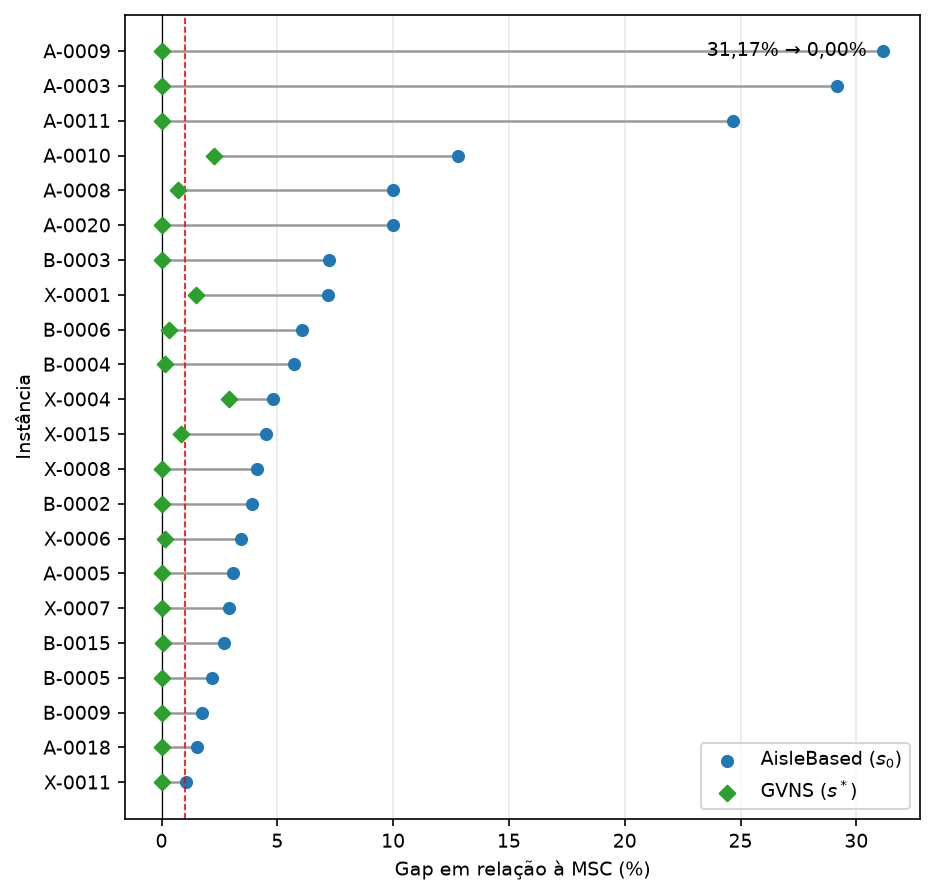

,dataset,instance,gap_s0,gap_gvns_med,reducao_pp
0,x,instance_0011,1.037736,0.000000,1.037736
1,a,instance_0018,1.535836,0.000000,1.535836
2,b,instance_0009,1.731602,0.000000,1.731602
3,b,instance_0005,2.173913,0.000000,2.173913
4,b,instance_0015,2.694182,0.042992,2.651189
5,x,instance_0007,2.924897,0.000000,2.924897
6,a,instance_0005,3.092059,0.000000,3.092059
7,x,instance_0006,3.435096,0.148920,3.286175
8,b,instance_0002,3.904546,0.040262,3.864285
9,x,instance_0008,4.112576,0.000000,4.112576


In [8]:
df_f1 = df_par[df_par["gap_s0"] > 1.0 + TOL].sort_values("gap_s0", ascending=True).reset_index(drop=True)
print(f"{len(df_f1)} instâncias com gap do AisleBased > 1%")

fig, ax = plt.subplots(figsize=(FIG_W, max(FIG_H1, 0.22 * len(df_f1) + 1.2)))
ys = np.arange(len(df_f1))
ds_style = {"a": "o", "b": "s", "x": "^"}
for y, r in zip(ys, df_f1.itertuples()):
    ax.plot([r.gap_ils_vnd_med, r.gap_s0], [y, y], color="0.6", lw=1.2, zorder=1)
ax.scatter(df_f1["gap_s0"], ys, color=COLORS["aisle_based"], marker="o", s=28, zorder=2, label="AisleBased ($s_0$)")
ax.scatter(df_f1["gap_ils_vnd_med"], ys, color=COLORS["ils_vnd"], marker="D", s=28, zorder=3, label="ILS-VND ($s^*$)")
ax.set_yticks(ys)
ax.set_yticklabels([f"{DS_LABELS[r.dataset]}-{r.instance.split('_')[-1]}" for r in df_f1.itertuples()])
ax.set_xlabel("Gap em relação à MSC (%)")
ax.set_ylabel("Instância")
ax.axvline(1.0, color="red", ls="--", lw=0.8)
ax.axvline(0.0, color="black", lw=0.6)
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower right")
if len(df_f1):
    _top = df_f1.iloc[-1]
    ax.annotate(f"{_top.gap_s0:.2f}% → {_top.gap_ils_vnd_med:.2f}%".replace(".", ","),
                xy=(_top.gap_s0, len(df_f1) - 1), xytext=(-8, 0), textcoords="offset points", va="center",
                ha="right", fontsize=FONT_MIN)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_2_1.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "fig_2_1.png", bbox_inches="tight")
df_f1.to_csv(OUTPUT_DIR / "fig_2_1_dados.csv", index=False)
plt.show()
display(df_f1[["dataset", "instance", "gap_s0", "gap_ils_vnd_med", "reducao_pp"]])


## 9. Figura 2.2: Faixas de Qualidade Antes e Depois do ILS-VND

Faixas: $\text{Gap} \le 0\%$ (MSC igualada/superada), $0\% < \text{Gap} \le 1\%$, $1\% < \text{Gap} \le 5\%$ e $\text{Gap} > 5\%$. Depois = ILS-VND (média das 5 réplicas).

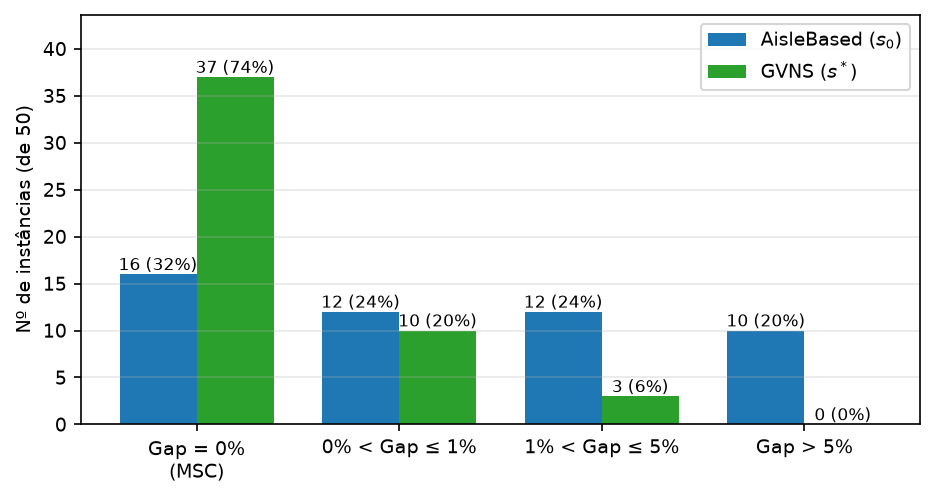

,AisleBased ($s_0$),GVNS ($s^*$)
Gap = 0% (MSC),16,37
0% < Gap ≤ 1%,12,10
1% < Gap ≤ 5%,12,3
Gap > 5%,10,0


In [9]:
FAIXAS = ["Gap = 0%\n(MSC)", "0% < Gap ≤ 1%", "1% < Gap ≤ 5%", "Gap > 5%"]
def faixa(g):
    if g <= TOL: return 0
    if g <= 1.0 + TOL: return 1
    if g <= 5.0 + TOL: return 2
    return 3

contagens = {}
for nome, col in [("AisleBased ($s_0$)", "gap_s0"), ("ILS-VND ($s^*$)", "gap_ils_vnd_med")]:
    contagens[nome] = np.bincount(df_par[col].map(faixa), minlength=4)
df_f2 = pd.DataFrame(contagens, index=[f.replace("\n", " ") for f in FAIXAS])
df_f2.to_csv(OUTPUT_DIR / "fig_2_2_dados.csv")

fig, ax = plt.subplots(figsize=(FIG_W, FIG_H2))
x = np.arange(4); w = 0.38
cores = [COLORS["aisle_based"], COLORS["ils_vnd"]]
for k, (nome, vals) in enumerate(contagens.items()):
    bars = ax.bar(x + (k - 0.5) * w, vals, w, label=nome, color=cores[k])
    for b, v in zip(bars, vals):
        ax.annotate(f"{v} ({100 * v / len(df_par):.0f}%)", (b.get_x() + b.get_width() / 2, v),
                    xytext=(0, 2), textcoords="offset points", ha="center", fontsize=FONT_MIN - 1)
ax.set_xticks(x); ax.set_xticklabels(FAIXAS)
ax.set_ylabel("Nº de instâncias (de 50)")
ax.set_ylim(0, max(max(v) for v in contagens.values()) * 1.18)
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_2_2.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "fig_2_2.png", bbox_inches="tight")
plt.show()
display(df_f2)


## 10. Verificações Finais

In [10]:
_checks = []
def check(nome, cond, detalhe=""):
    _checks.append({"verificação": nome, "status": "ok" if cond else "FALHA", "detalhe": detalhe})

check("50 instâncias pareadas", len(df_par) == 50, f"{len(df_par)}")
check(f"{N_REPS} réplicas ILS-VND por instância", set(_v["n_runs"]) == {N_REPS}, str(set(_v["n_runs"])))
check("sem ausentes", not df_par.isna().any().any())
check("ILS-VND melhor <= ILS-VND média", bool((df_par.gap_ils_vnd_best <= df_par.gap_ils_vnd_med + TOL).all()))
for ds in DATASETS + [None]:
    sub = df_par[df_par["dataset"] == ds] if ds else df_par
    w, t, l, _ = resumo_pareado(sub["gap_ils_vnd_med"].values, sub["gap_s0"].values)
    check(f"V+E+D=N — {DS_LABELS[ds] if ds else 'Geral'}", w + t + l == len(sub))
check("Fig 2.2 soma 50 (antes e depois)", all(v.sum() == 50 for v in contagens.values()))
for f in sorted(OUTPUT_DIR.glob("tab_2_*.tex")):
    erros = verificar_tex(f.read_text(encoding="utf-8").split("\n\n")[0], f.name)
    check(f"estrutura .tex — {f.name}", not erros, "; ".join(erros))
df_checks = pd.DataFrame(_checks)
display(df_checks)
if (df_checks["status"] == "FALHA").any():
    raise AssertionError("Falha em verificações!")
for f in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {f.name:30s} {f.stat().st_size:8d} bytes")


,verificação,status,detalhe
0,50 instâncias pareadas,ok,50
1,5 réplicas GVNS por instância,ok,{5}
2,sem ausentes,ok,
3,GVNS melhor <= GVNS média,ok,
4,V+E+D=N — A,ok,
5,V+E+D=N — B,ok,
6,V+E+D=N — X,ok,
7,V+E+D=N — Geral,ok,
8,Fig 2.2 soma 50 (antes e depois),ok,
9,estrutura .tex — tab_2_1.tex,ok,


  fig_2_1.pdf                       37999 bytes
  fig_2_1.png                      159653 bytes
  fig_2_1_dados.csv                  2430 bytes
  fig_2_2.pdf                       32498 bytes
  fig_2_2.png                      104436 bytes
  fig_2_2_dados.csv                   111 bytes
  tab_2_1.csv                        1410 bytes
  tab_2_1.tex                        1397 bytes
  tab_2_2.csv                         411 bytes
  tab_2_2.tex                         739 bytes
  tab_2_3.csv                         506 bytes
  tab_2_3.tex                        1038 bytes
